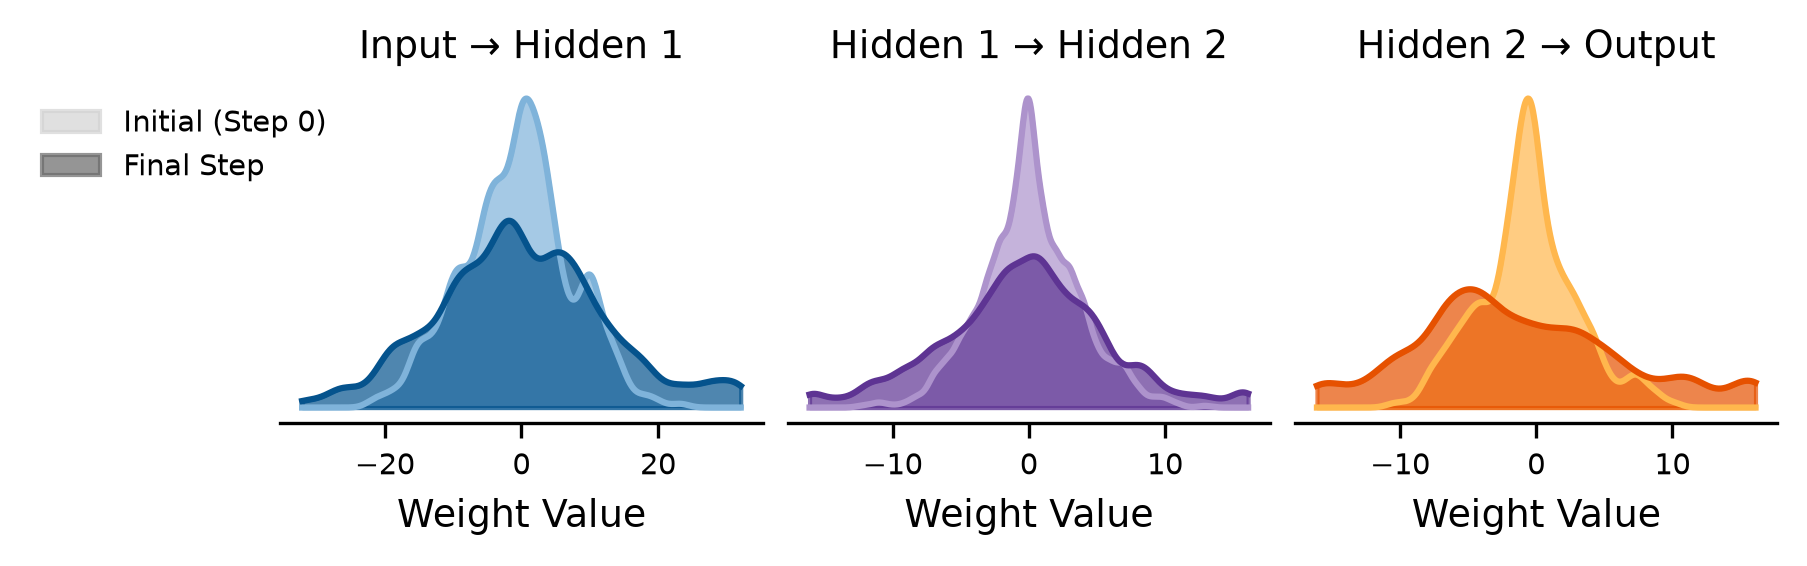

In [39]:
%matplotlib inline
import os
import pickle
import sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import gaussian_kde

# Make sure summarize_runs can be imported for latexify and colors
sys.path.append('../scripts')
import summarize_runs as sr

def load_weights(path):
    name = os.path.splitext(os.path.basename(path))[0]
    with open(os.path.join(os.path.dirname(path), "trainlog.pkl"), "rb") as f:
        meta = pickle.load(f)
        
    shape = tuple(meta["arrays"][name])
    actual_shape = (-1,) + shape[1:] # Infer logged batch dimension automatically
    
    weights = np.fromfile(path, dtype="float64").reshape(actual_shape)
    return weights.reshape(weights.shape[0], -1)

def plot_weight_distributions(base_dir):
    weight_files = [
        ('Input → Hidden 1', 'weights_in_hid1_fine.dat'),
        ('Hidden 1 → Hidden 2', 'weights_hid1_hid2_fine.dat'),
        ('Hidden 2 → Output', 'weights_hid2_out_fine.dat')
    ]

    color_pairs = [
        (sr.COLOR_TRAIN_LIGHT, sr.COLOR_TRAIN), 
        (sr.COLOR_VAL_LIGHT, sr.COLOR_VAL),     
        ('#FFB74D', '#E65100')                  
    ]

    # Apply publication styling
    sr.latexify(width_fraction=1.0, base_font_size=9, height_ratio=0.3)
    
    # Use constrained_layout=True just like summarize_runs.py does
    fig, axes = plt.subplots(1, 3, sharey=False, constrained_layout=True)

    for ax, (title, filename), (color_light, color_dark) in zip(axes, weight_files, color_pairs):
        path = os.path.join(base_dir, filename)
        weights_flat = load_weights(path)
        
        w_start = weights_flat[0]
        w_final = weights_flat[-1]
        
        x_min = min(w_start.min(), w_final.min()) - 0.1
        x_max = max(w_start.max(), w_final.max()) + 0.1
        x_grid = np.linspace(x_min, x_max, 500)
        
        kde_start = gaussian_kde(w_start)
        y_start = kde_start(x_grid)
        
        kde_final = gaussian_kde(w_final)
        y_final = kde_final(x_grid)
        
        ax.fill_between(x_grid, 0, y_start, color=color_light, alpha=0.7)
        ax.plot(x_grid, y_start, color=color_light, linewidth=1.5)
        
        ax.fill_between(x_grid, 0, y_final, color=color_dark, alpha=0.7)
        ax.plot(x_grid, y_final, color=color_dark, linewidth=1.5)
        
        ax.set_title(title)
        ax.set_xlabel("Weight Value")
        
        ax.set_yticks([])
        ax.spines['left'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['top'].set_visible(False)

    legend_elements = [
        Patch(facecolor='lightgray', edgecolor='lightgray', alpha=0.7, label='Initial (Step 0)'),
        Patch(facecolor='dimgray', edgecolor='dimgray', alpha=0.7, label='Final Step')
    ]
    
    # Let constrained_layout handle the legend space dynamically
    axes[0].legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(0.15, 1.0), frameon=False)

    plt.show()
    return fig

# --- Usage Example ---
base_dir = '../dynapse_results/mnist1d/full/201175_0'
fig = plot_weight_distributions(base_dir)
